In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

In [2]:
def smi2conf(smiles):
    '''Convert SMILES to rdkit.Mol with 3D coordinates'''
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol = Chem.AddHs(mol)   #Agregar Hidrógenos
        AllChem.EmbedMolecule(mol) #Generar conformaciones
        AllChem.MMFFOptimizeMolecule(mol, maxIters=200) #Campo de fuerza
        return mol
    else:
        return None

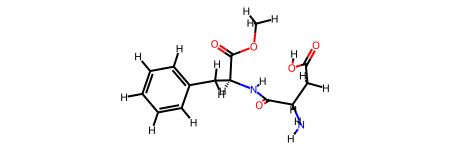

In [3]:
L_aspartame = 'COC(=O)[C@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(=O)O)N'
L_aspartame = smi2conf(L_aspartame)
L_aspartame

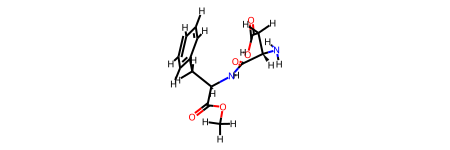

In [4]:
D_aspartame = 'COC(=O)[C@@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(=O)O)N'
D_aspartame = smi2conf(D_aspartame)
D_aspartame

#pymol

In [5]:
ps = rdDistGeom.ETKDGv3()
ps.clearConfs= False

cid_L = rdDistGeom.EmbedMolecule(L_aspartame,ps)
cid_D = rdDistGeom.EmbedMolecule(D_aspartame,ps)
#

In [6]:
print(cid_L)
print(cid_D)

1
1


Imprimimos el primer conformero

In [7]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(L_aspartame,v,confId=0)
#v.setStyle({'model': 0, 'cartoon':{'colorscheme':'pinkCarbon'}}) # Target the second model
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [8]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(D_aspartame,v,confId=1)
v.setStyle({'model': 0, 'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
#v.setStyle({'line':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [9]:

v3 = py3Dmol.view(width=400,height=400)
v3.removeAllModels()

# Display the aligned molecules using py3Dmol
rmsd = AllChem.AlignMol(L_aspartame, D_aspartame)

# Add the first molecule (reference)
IPythonConsole.addMolToView(L_aspartame, v3, confId=0)


# Add the second molecule (aligned)
IPythonConsole.addMolToView(D_aspartame, v3, confId=0)
v3.setStyle({'model':0}, {'stick':{'colorscheme':'greenCarbon'}}) # Style as sticks for better visualization
v3.addStyle({'model':1}, {'stick':{'colorscheme':'pinkCarbon'}}) # Style as sticks for better visualization
v3.zoomTo()
v3.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [10]:
# Align the molecules using the chiral centers as anchors
# First, find the chiral centers
chiral_centers_L = [atom.GetIdx() for atom in L_aspartame.GetAtoms() if atom.HasProp('_ChiralityPossible')]
chiral_centers_D = [atom.GetIdx() for atom in D_aspartame.GetAtoms() if atom.HasProp('_ChiralityPossible')]

# Perform the alignment using the chiral centers
rmsd = AllChem.AlignMol(L_aspartame, D_aspartame, atomMap=list(zip(chiral_centers_L, chiral_centers_D)))


# Visualize the aligned molecules using py3Dmol
v1 = py3Dmol.view(width=800,height=800)
v1.removeAllModels()

IPythonConsole.addMolToView(L_aspartame, v1, confId=0)
IPythonConsole.addMolToView(D_aspartame, v1, confId=0)

v1.setStyle({'model':0}, {'stick':{'colorscheme':'greenCarbon'}}) # Style as sticks for better visualization
v1.addStyle({'model':1}, {'stick':{'colorscheme':'pinkCarbon'}}) # Style as sticks for better visualization
v1.zoomTo()
v1.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [11]:
def MolTo3DView(mol, size=(300, 300), style="stick", surface=False, opacity=0.5):
    assert style in ('line', 'stick', 'sphere', 'carton')
    mblock = Chem.MolToMolBlock(mol)
    viewer = py3Dmol.view(width=size[0], height=size[1])
    viewer.addModel(mblock, 'mol')
    viewer.setStyle({style:{}})
    if surface:
        viewer.addSurface(py3Dmol.SAS, {'opacity': opacity})
    viewer.zoomTo()
    return viewer

In [12]:
conf = smi2conf(Chem.MolToSmiles(L_aspartame))
viewer = MolTo3DView(conf, size=(1200, 600), style='stick', surface=True, opacity=.4)#'stick', 'sphere')
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [13]:
conf = smi2conf(Chem.MolToSmiles(L_aspartame))
viewer = MolTo3DView(conf, size=(1200, 600), style='sphere')#'stick', 'sphere')
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.